In [9]:
# %pip install xgboost
# %pip install missingno

# Preliminary Analysis and Building of the Model

In [10]:
import pandas as pd
import numpy as np
import os
import kagglehub
import seaborn as sbn
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report
from collections import defaultdict
import re
from typing import Tuple
import missingno as msno

## Download and Explore the `results` dataset




In [11]:
path = kagglehub.dataset_download("martj42/international-football-results-from-1872-to-2017")

results = pd.read_csv(os.path.join(path, 'results.csv'))

results

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False
...,...,...,...,...,...,...,...,...,...
49940,2026-10-06,Belize,French Guiana,0,1,CONCACAF Nations League,Belmopan,Belize,False
49941,2026-10-06,Turks and Caicos Islands,Montserrat,1,4,CONCACAF Nations League,Providenciales,Turks and Caicos Islands,False
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,CONCACAF Nations League,North Sound,Antigua and Barbuda,False
49943,2026-10-06,Saint Martin,Bahamas,6,0,CONCACAF Nations League,St Croix,United States Virgin Islands,True


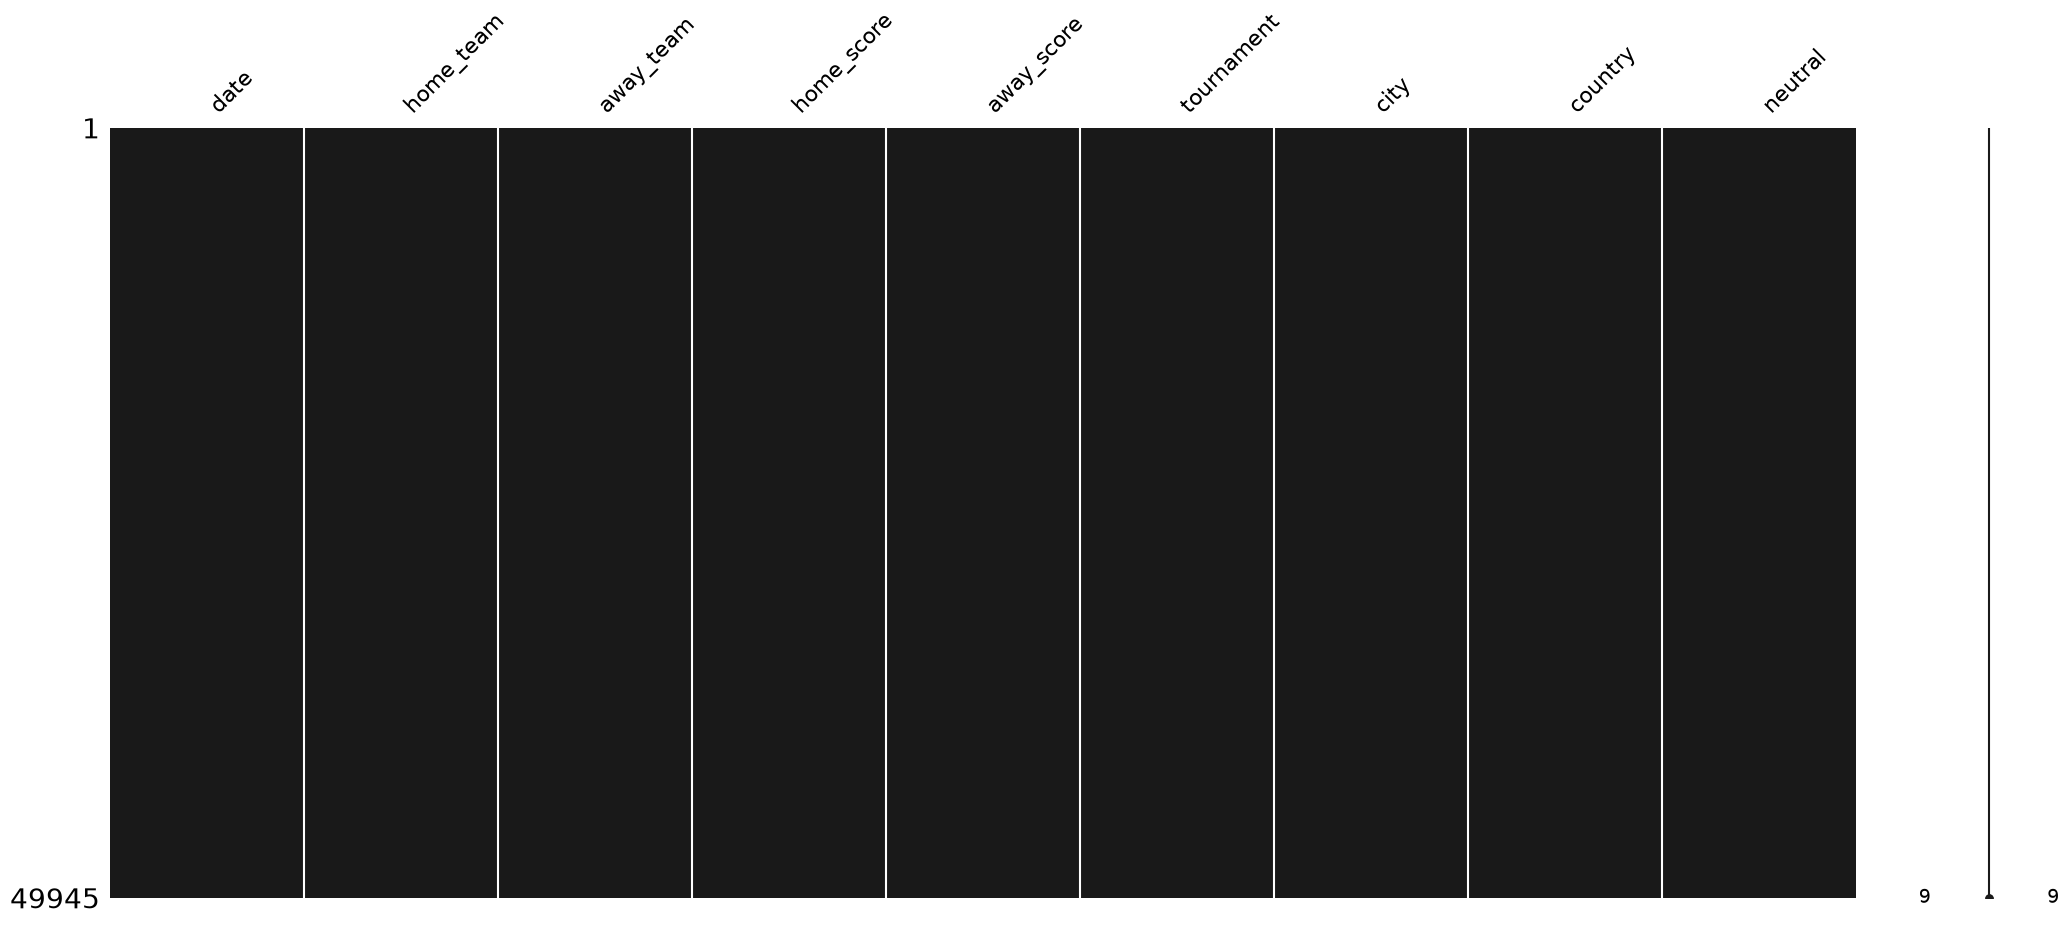

In [12]:
msno.matrix(results, color=(0.1, 0.1, 0.1))
# msno.matrix(results, sparkline=False, color=(0.1, 0.1, 0.1))
plt.show()

In [13]:
print(results.shape)
row = 49355
results.iloc[row:row+1]


(49945, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49355,2026-06-02,Croatia,Belgium,0,2,Friendly,Rijeka,Croatia,False


In [14]:
# Mapping inconsistent team names to match the world_cup_2026_groups definition
team_name_map = {
    "Republic of Ireland": "Ireland",
    "Cape Verde": "Cabo Verde",
    "Czech Republic": "Czechia"
}

# Standardize names in the main results DataFrame
results['home_team'] = results['home_team'].replace(team_name_map)
results['away_team'] = results['away_team'].replace(team_name_map)

In [15]:
# results[(results['date'] > '2003-01-01') & (results['date'] < '2026-06-11') & (results['home_team'].isin(wc_teams) & results['away_team'].isin(wc_teams)) ]
results[(results['date'] > '2023-01-01') & (results['date'] < '2026-06-11')]

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
45847,2023-01-02,Thailand,Cambodia,3,1,AFF Championship,Pathum Thani,Thailand,False
45848,2023-01-02,Philippines,Indonesia,1,2,AFF Championship,Manila,Philippines,False
45849,2023-01-03,Vietnam,Myanmar,3,0,AFF Championship,Hanoi,Vietnam,False
45850,2023-01-03,Malaysia,Singapore,4,1,AFF Championship,Kuala Lumpur,Malaysia,False
45851,2023-01-06,Iraq,Oman,0,0,Gulf Cup,Basra,Iraq,False
...,...,...,...,...,...,...,...,...,...
49470,2026-06-09,Iraq,Venezuela,0,2,Friendly,Bridgeview,United States,True
49471,2026-06-10,Bolivia,Algeria,0,4,Friendly,Kansas City,United States,True
49472,2026-06-10,England,Costa Rica,3,0,Friendly,Orlando,United States,True
49473,2026-06-10,Portugal,Nigeria,2,1,Friendly,Leiria,Portugal,False


In [16]:
results['date'] = pd.to_datetime(results['date'])
results = results.drop(columns=['city', 'country'])
results = results.sort_values('date').reset_index(drop=True)
# results = results[(results['date'] > '1979-01-01') & (results['date'] < '2026-06-11')]
results = results[results['date'] < '2026-06-11']
results

,date,home_team,away_team,home_score,away_score,tournament,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,False
1,1873-03-08,England,Scotland,4,2,Friendly,False
2,1874-03-07,Scotland,England,2,1,Friendly,False
3,1875-03-06,England,Scotland,2,2,Friendly,False
4,1876-03-04,Scotland,England,3,0,Friendly,False
...,...,...,...,...,...,...,...
49470,2026-06-09,Ethiopia,Malawi,1,1,Friendly,False
49471,2026-06-10,Bolivia,Algeria,0,4,Friendly,True
49472,2026-06-10,England,Costa Rica,3,0,Friendly,True
49473,2026-06-10,Portugal,Nigeria,2,1,Friendly,False


In [17]:
# print(results['tournament'].unique())
# print(results[(results['date'] > '1970-01-01') & (results['date'] < '2026-06-11')]['tournament'].unique())
print(len(results[(results['date'] > '1970-01-01') & (results['date'] < '2026-06-11')]['tournament'].unique()))

202


## Get the ELO scores
Implements the logic to compute dynamic ELO score for each team.\
I need to "train" the Elo scores since the beginning of match records, as the scores tend to converge to a team's true strength relative to its competitors only after about 30 matches. Otherwise they should be considered provisional.

In [18]:
class EloTracker:
    """
    A class to track and calculate official World Football Elo Ratings.
    """
    def __init__(self, base_rating: float = 1500.0, home_advantage: float = 100.0):
        self.ratings = {}
        self.base_rating = base_rating
        self.home_advantage = home_advantage

    def get_rating(self, team: str) -> float:
        """Safely fetch a team's current rating, defaulting to base_rating."""
        return self.ratings.get(team, self.base_rating)

    def get_k_weight(self, tournament: str) -> int:
        """Method to map tournament types to K-factors."""
        t_lower = str(tournament).lower()
        if 'world cup' in t_lower and 'qual' not in t_lower:
            return 60
        elif any(x in t_lower for x in ['copa america', 'euros', 'asian cup', 'africa cup']):
            return 50
        elif 'qualification' in t_lower or 'qualifiers' in t_lower:
            return 40
        elif 'friendly' in t_lower:
            return 20
        return 30

    def get_goal_multiplier(self, home_score: int, away_score: int) -> float:
        """Method to calculate the margin of victory multiplier."""
        n = abs(home_score - away_score)
        if n <= 1:
            return 1.0
        elif n == 2:
            return 1.5
        elif n == 3:
            return 1.75
        return 1.75 + ((n - 3) / 8.0)

    def process_match(self, home_team: str, away_team: str, home_score: int, away_score: int,
                      tournament: str, is_neutral: bool = False) -> Tuple[float, float]:
        """
        Calculates the pre-match ratings, updates the internal dictionary based on the result,
        and returns the pre-match ratings for feature engineering.
        """
        # 1. Fetch current pre-match ratings
        h_elo = self.get_rating(home_team)
        a_elo = self.get_rating(away_team)

        # 2. Apply Home Advantage (if not a neutral venue)
        h_adv = 0 if is_neutral else self.home_advantage

        # 3. Calculate Expected Result (We)
        dr_home = (h_elo + h_adv) - a_elo
        dr_away = a_elo - (h_elo + h_adv)

        we_home = 1 / (10 ** (-dr_home / 400) + 1)
        we_away = 1 / (10 ** (-dr_away / 400) + 1)

        # 4. Determine Actual Result (W)
        if home_score > away_score:
            w_home, w_away = 1.0, 0.0
        elif home_score < away_score:
            w_home, w_away = 0.0, 1.0
        else:
            w_home, w_away = 0.5, 0.5

        # 5. Calculate Final K Factor
        final_k = self.get_k_weight(tournament) * self.get_goal_multiplier(home_score, away_score)

        # 6. Update internal dictionary with new ratings
        self.ratings[home_team] = h_elo + final_k * (w_home - we_home)
        self.ratings[away_team] = a_elo + final_k * (w_away - we_away)

        # 7. Return the PRE-MATCH ratings so we can log them for XGBoost
        return h_elo, a_elo

In [19]:
# 1. Initialize the Elo tracker
elo_score = EloTracker(base_rating=1500, home_advantage=100)

# Arrays to store the features we extract
home_pre_elos = []
away_pre_elos = []

# 2. Iterate through historical matches chronologically
for idx, row in results.iterrows():

    # Process the match and get the pre-match ratings simultaneously
    h_pre, a_pre = elo_score.process_match(
        home_team=row['home_team'],
        away_team=row['away_team'],
        home_score=row['home_score'],
        away_score=row['away_score'],
        tournament=row['tournament'],
        is_neutral=row['neutral']  # Assuming you have a boolean column for this
    )

    # Save the features
    home_pre_elos.append(h_pre)
    away_pre_elos.append(a_pre)

# 3. Attach to your DataFrame
results['home_pre_elo'] = home_pre_elos
results['away_pre_elo'] = away_pre_elos

# To use the final dictionary in your Monte Carlo simulations later:
current_elos = elo_score.ratings

results['tournament_k'] = results['tournament'].apply(elo_score.get_k_weight)

new_order = ['date', 'home_team', 'away_team', 'home_pre_elo', 'away_pre_elo',
       'home_score', 'away_score', 'tournament', 'tournament_k', 'neutral']
results = results.reindex(columns=new_order)
results

,date,home_team,away_team,home_pre_elo,away_pre_elo,home_score,away_score,tournament,tournament_k,neutral
0,1872-11-30,Scotland,England,1500.000000,1500.000000,0,0,Friendly,20,False
1,1873-03-08,England,Scotland,1502.801300,1497.198700,4,2,Friendly,20,False
2,1874-03-07,Scotland,England,1486.622531,1513.377469,2,1,Friendly,20,False
3,1875-03-06,England,Scotland,1505.454946,1494.545054,2,2,Friendly,20,False
4,1876-03-04,Scotland,England,1497.633108,1502.366892,3,0,Friendly,20,False
...,...,...,...,...,...,...,...,...,...,...
49470,2026-06-09,Ethiopia,Malawi,1417.483466,1437.137360,1,1,Friendly,20,False
49471,2026-06-10,Bolivia,Algeria,1727.629852,1882.626006,0,4,Friendly,20,True
49472,2026-06-10,England,Costa Rica,2075.080984,1730.310013,3,0,Friendly,20,True
49473,2026-06-10,Portugal,Nigeria,2033.363491,1850.734806,2,1,Friendly,20,False


In [20]:
elo_series = pd.Series(current_elos).sort_values(ascending=False)
print("TOP 20 ELO RATINGS")
print(elo_series.head(20))

TOP 20 ELO RATINGS
Spain          2177.338241
Argentina      2170.014007
France         2127.095202
England        2079.309783
Brazil         2063.351639
Colombia       2048.014098
Portugal       2036.648486
Ecuador        2020.080748
Netherlands    2011.640028
Germany        2003.868381
Japan          1991.176395
Morocco        1985.690894
Belgium        1980.780940
Croatia        1976.201779
Uruguay        1968.741365
Norway         1954.752511
Mexico         1951.742332
Turkey         1950.913902
Switzerland    1939.258002
Italy          1923.685571
dtype: float64


## Prepare data for XGBoost
Now I build the dataframe for XGBoost training.

In [21]:
results_xgb = results.copy()
results_xgb = results_xgb.drop(columns=['home_team', 'away_team', 'tournament' ])

results_xgb['elo_pre_diff'] = results_xgb['home_pre_elo'] - results_xgb['away_pre_elo']

match_outcome = []
for idx, row in results.iterrows():
    if row['home_score'] > row['away_score']:
        match_outcome.append(1)
    elif row['home_score'] < row['away_score']:
        match_outcome.append(2)
    else:
        match_outcome.append(0)

results_xgb['match_outcome'] = match_outcome
results_xgb

features = ['date', 'home_pre_elo', 'away_pre_elo', 'elo_pre_diff','match_outcome', 'tournament_k', 'neutral']
results_xgb = results_xgb.reindex(columns=features)

results_xgb['neutral'] = results_xgb['neutral'].astype(int)

results_xgb = pd.get_dummies(results_xgb, columns=['tournament_k'], prefix='k', dtype=int)

results_xgb = results_xgb[ results_xgb['date'] > '1950-01-01' ].reset_index(drop=True)

results_xgb

,date,home_pre_elo,away_pre_elo,elo_pre_diff,match_outcome,neutral,k_20,k_30,k_40,k_50,k_60
0,1950-01-24,1516.057918,1487.736793,28.321124,1,0,1,0,0,0,0
1,1950-02-17,1538.889970,1300.170808,238.719162,1,0,0,1,0,0,0
2,1950-02-26,1356.216667,1506.126053,-149.909385,1,0,1,0,0,0,0
3,1950-02-26,1554.323986,1500.000000,54.323986,1,0,1,0,0,0,0
4,1950-03-05,1850.406201,1460.541207,389.864993,1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
46132,2026-06-09,1417.483466,1437.137360,-19.653893,0,0,1,0,0,0,0
46133,2026-06-10,1727.629852,1882.626006,-154.996154,2,1,1,0,0,0,0
46134,2026-06-10,2075.080984,1730.310013,344.770972,1,1,1,0,0,0,0
46135,2026-06-10,2033.363491,1850.734806,182.628685,1,0,1,0,0,0,0


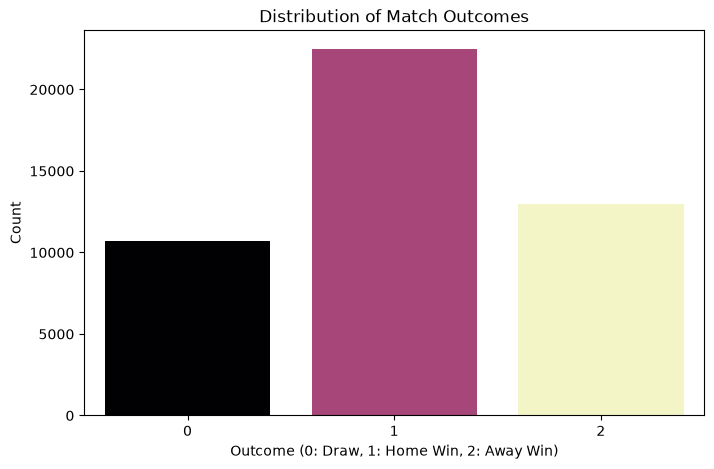

In [22]:
# Look for match outcome imbalances"""
plt.figure(figsize=(8, 5))
sbn.countplot(data=results_xgb, x='match_outcome', hue='match_outcome', palette='magma', legend=False)
plt.title('Distribution of Match Outcomes')
plt.xlabel('Outcome (0: Draw, 1: Home Win, 2: Away Win)')
plt.ylabel('Count')
plt.show()

### Split data into Training and Test Sets

In [23]:
train_res = results_xgb[ results_xgb['date'] < '2022-11-20' ]
test_res = results_xgb[ (results_xgb['date'] > '2022-11-20') & (results_xgb['date'] < '2026-06-11') ]
# test_res = results_xgb[ (results_xgb['date'] > '2022-11-20') & (results_xgb['date'] < '2026-06-11') & (results_xgb['match_outcome'] != 0) ]
# test_res = results_xgb[ (results_xgb['date'] > '2022-11-20')

drop_cols = ['date', 'match_outcome']

X_train = train_res.drop(columns=drop_cols)
y_train = train_res['match_outcome']

X_test = test_res.drop(columns=drop_cols)
y_test = test_res['match_outcome']

In [24]:
X_train.head()

,home_pre_elo,away_pre_elo,elo_pre_diff,neutral,k_20,k_30,k_40,k_50,k_60
0,1516.057918,1487.736793,28.321124,0,1,0,0,0,0
1,1538.889970,1300.170808,238.719162,0,0,1,0,0,0
2,1356.216667,1506.126053,-149.909385,0,1,0,0,0,0
3,1554.323986,1500.000000,54.323986,0,1,0,0,0,0
4,1850.406201,1460.541207,389.864993,0,1,0,0,0,0


### Train and Evaluate the Model

In [25]:
model = XGBClassifier(
    n_estimators=300,       # Number of decision trees
    objective='multi:softprob',
    learning_rate=0.1,     # Slow learning rate for better generalization
    max_depth=4,            # Keep trees shallow to prevent overfitting
    # subsample=0.8,          # Use 80% of data per tree to add randomness
    random_state=42)

model.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [26]:
predicted_probabilities = model.predict_proba(X_test)
predictions = model.predict(X_test)

Accuracy on Test Set: 0.6023675006725854
Log Loss (the lower the better): 0.8828052878379822
              precision    recall  f1-score   support

           0       0.29      0.02      0.03       852
           1       0.62      0.87      0.72      1758
           2       0.58      0.62      0.60      1107

    accuracy                           0.60      3717
   macro avg       0.50      0.50      0.45      3717
weighted avg       0.53      0.60      0.53      3717



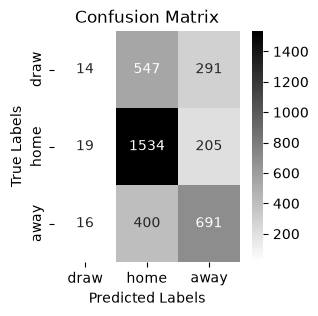

In [27]:
print("Accuracy on Test Set:", accuracy_score(y_test, predictions))
print("Log Loss (the lower the better):", log_loss(y_test, predicted_probabilities, labels=[0,1,2]))

print(classification_report(y_test, predictions))

conf_m = confusion_matrix(y_test, predictions, labels = [0, 1, 2])
plt.figure(figsize=(3, 3))  # Adjust size to accommodate 8x8 matrix
sbn.heatmap(conf_m, annot=True, fmt="d",
            xticklabels=['draw', 'home', 'away'],
            yticklabels=['draw', 'home', 'away'], cmap = plt.cm.gray_r)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

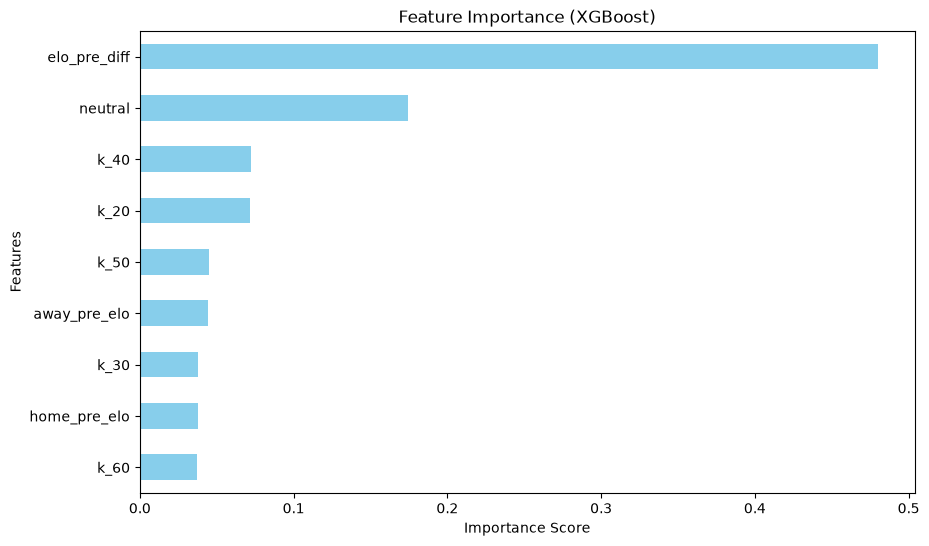

Feature Importances:
elo_pre_diff    0.480049
neutral         0.174271
k_40            0.072014
k_20            0.071822
k_50            0.044737
away_pre_elo    0.044322
k_30            0.037948
home_pre_elo    0.037724
k_60            0.037113
dtype: float32


In [28]:
# Get feature importances from the model
importances = model.feature_importances_
feature_names = X_train.columns

# Create a pandas series for easy plotting
feature_importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=True)

# Plotting
plt.figure(figsize=(10, 6))
feature_importance_series.plot(kind='barh', color='skyblue')
plt.title('Feature Importance (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Print the raw values
print("Feature Importances:")
print(feature_importance_series.sort_values(ascending=False))

### Re-train the model on all matches available
Now I re-train the model using all data available, including the matches just used to assess the model performance. \
Since the importance of home and away teams' ELO is low, I decide to consider only ELO difference during the training proces.

In [29]:
train_res = results_xgb[ results_xgb['date'] < '2026-06-11' ]

drop_cols = ['date', 'home_pre_elo', 'away_pre_elo', 'match_outcome']

X_train = train_res.drop(columns=drop_cols)
y_train = train_res['match_outcome']


In [30]:
X_train.head()

,elo_pre_diff,neutral,k_20,k_30,k_40,k_50,k_60
0,28.321124,0,1,0,0,0,0
1,238.719162,0,0,1,0,0,0
2,-149.909385,0,1,0,0,0,0
3,54.323986,0,1,0,0,0,0
4,389.864993,0,1,0,0,0,0


In [31]:
wc_26_predictor = XGBClassifier(
    n_estimators=300,       # Number of decision trees
    objective='multi:softprob',
    learning_rate=0.1,     # Slow learning rate for better generalization
    max_depth=4,            # Keep trees shallow to prevent overfitting
    # subsample=0.8,          # Use 80% of data per tree to add randomness
    random_state=42)

wc_26_predictor.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

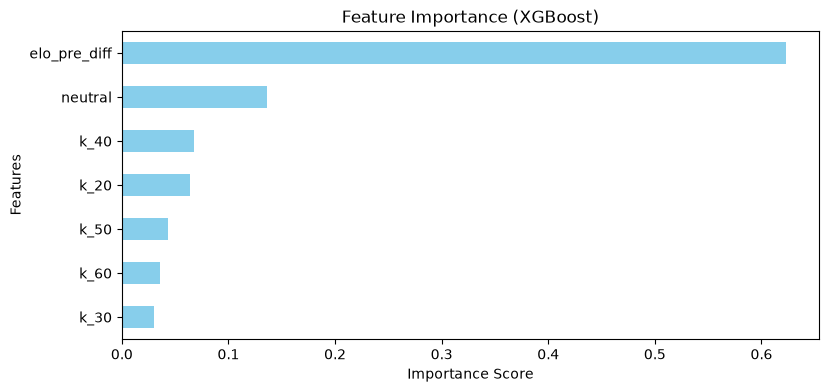

Feature Importances:
elo_pre_diff    0.623155
neutral         0.136359
k_40            0.067996
k_20            0.063516
k_50            0.043226
k_60            0.035720
k_30            0.030029
dtype: float32


In [32]:
# Get feature importances from the model
importances = wc_26_predictor.feature_importances_
feature_names = X_train.columns

# Create a pandas series for easy plotting
feature_importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=True)

# Plotting
plt.figure(figsize=(9,4))
feature_importance_series.plot(kind='barh', color='skyblue')
plt.title('Feature Importance (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Print the raw values
print("Feature Importances:")
print(feature_importance_series.sort_values(ascending=False))

# Simulate the World Cup
Now I build the framework needed to simulate the whole tournament.

## Simulate a single match

In [33]:
wc_26_groups = {
    "Group A": ["Mexico", "South Africa", "South Korea", "Czechia"],
    "Group B": ["Canada", "Bosnia and Herzegovina", "Qatar", "Switzerland"],
    "Group C": ["Brazil", "Morocco", "Haiti", "Scotland"],
    "Group D": ["United States", "Paraguay", "Australia", "Turkey"],
    "Group E": ["Germany", "Curaçao", "Ivory Coast", "Ecuador"],
    "Group F": ["Netherlands", "Japan", "Sweden", "Tunisia"],
    "Group G": ["Belgium", "Egypt", "Iran", "New Zealand"],
    "Group H": ["Spain", "Cabo Verde", "Saudi Arabia", "Uruguay"],
    "Group I": ["France", "Senegal", "Iraq", "Norway"],
    "Group J": ["Argentina", "Algeria", "Austria", "Jordan"],
    "Group K": ["Portugal", "DR Congo", "Uzbekistan", "Colombia"],
    "Group L": ["England", "Croatia", "Ghana", "Panama"]
}

In [34]:
# ==========================================
# 1. SINGLE MATCH SIMULATION
# ==========================================
def simulate_match(team_h, team_a, elos, is_knockout=False):
    # Retrieves current Elos, builds the feature row, and uses XGBoost to predict.

    # 1. Look up the current Elos for both teams
    elo_h = elos.get(team_h, 1500)
    elo_a = elos.get(team_a, 1500)

    # 2. Build the feature array exactly how XGBoost expects it
    # [elo_home, elo_away, neutral, k_20, k_30, k_40, k_50, k_60]
    # Assuming World Cup matches are K_60 and Neutral=1

    match_ = pd.DataFrame([[elo_h-elo_a, 1, 0, 0, 0, 0, 1]],
                            columns=['elo_pre_diff', 'neutral',
                                     'k_20', 'k_30', 'k_40', 'k_50', 'k_60'])

    # 3. Get probabilities [0:Draw, 1:Home Win, 2:Away Win]
    probs = wc_26_predictor.predict_proba(match_)[0]

    rand_roll = np.random.rand()
    if is_knockout:
        # Re-distribute the draw probability for elimination games
        win_h = probs[1] + (probs[0] / 2)
        win_a = probs[2] + (probs[0] / 2)
        if rand_roll < win_h:
          return team_h
        else:
          return team_a
    else:
        # Standard group stage match (Draws allowed)
        if rand_roll < probs[1]:
          return team_h           # Team HOME wins
        elif rand_roll < probs[0] + probs[1]:
          return "Draw"
        else:
          return team_a                              # Team AWAY wins

In [35]:
# example of match simulation
team_1 = 'Brazil'
team_2 = 'Morocco'
n_sims = 10000

win_team_1 = 0
win_team_2 = 0
draw = 0

for _ in range(n_sims):
    result = simulate_match(team_1, team_2, current_elos)
    if result == team_1:
        win_team_1 += 1
    elif result == team_2:
        win_team_2 += 1
    else:
        draw += 1

print(f"{team_1} win: {(win_team_1/n_sims)*100:.2f}%")
print(f"Draw: {(draw/n_sims)*100:.2f}%")
print(f"{team_2} win: {(win_team_2/n_sims)*100:.2f}%")

Brazil win: 53.85%
Draw: 22.26%
Morocco win: 23.89%


## Simulate the Group Stage

In [36]:
# ==========================================
# 2. GROUP STAGE ENGINE (WITH ELO TIEBREAKER)
# ==========================================
def simulate_group(group, elos=current_elos):
    # Simulates a single group and returns the standings dictionary.
    points = {team: 0 for team in group}

    # Play every combination of teams in the group
    for i in range(len(group)):
        for j in range(i + 1, len(group)):
            result = simulate_match(group[i], group[j], elos, is_knockout=False)

            if result == group[i]:
                points[group[i]] += 3
            elif result == group[j]:
                points[group[j]] += 3
            else:
                points[group[i]] += 1
                points[group[j]] += 1

    # Sort teams by points first, then by their current Elo rating as a tiebreaker
    standings = sorted(points.keys(),
                          key=lambda x: (points[x], elos.get(x, 1500)),
                          reverse=True)

    # Create a sorted points dictionary based on the standings
    sorted_points = {team: points[team] for team in standings}

    # Return the group standings list and the sorted points dictionary
    return sorted_points

In [37]:
simulate_group(wc_26_groups['Group B'])

{'Switzerland': 7, 'Canada': 5, 'Qatar': 2, 'Bosnia and Herzegovina': 1}

In [38]:
def simulate_group_stage(groups, elos=current_elos):
    """
    Simulates the group stage for all 12 groups.
    Returns:
        all_standings: Dict of group_name -> sorted_points_dict
    """
    all_standings = {}

    # Simulate each group and store the results
    for group_id, teams in groups.items():
        label = group_id.split()[-1] if ' ' in group_id else group_id
        all_standings[label] = simulate_group(teams)

    return all_standings

In [39]:
all_standings = simulate_group_stage(wc_26_groups, current_elos)
all_standings

{'A': {'Mexico': 7, 'South Korea': 4, 'Czechia': 4, 'South Africa': 1},
 'B': {'Canada': 5, 'Switzerland': 4, 'Qatar': 4, 'Bosnia and Herzegovina': 3},
 'C': {'Brazil': 5, 'Morocco': 4, 'Scotland': 4, 'Haiti': 3},
 'D': {'Turkey': 9, 'Paraguay': 6, 'Australia': 1, 'United States': 1},
 'E': {'Germany': 9, 'Ecuador': 6, 'Ivory Coast': 3, 'Curaçao': 0},
 'F': {'Netherlands': 5, 'Japan': 5, 'Sweden': 2, 'Tunisia': 2},
 'G': {'Iran': 9, 'Belgium': 3, 'Egypt': 3, 'New Zealand': 3},
 'H': {'Spain': 6, 'Uruguay': 6, 'Saudi Arabia': 3, 'Cabo Verde': 3},
 'I': {'France': 7, 'Norway': 5, 'Senegal': 3, 'Iraq': 1},
 'J': {'Argentina': 6, 'Jordan': 5, 'Algeria': 4, 'Austria': 1},
 'K': {'Portugal': 9, 'DR Congo': 4, 'Uzbekistan': 3, 'Colombia': 1},
 'L': {'Croatia': 9, 'England': 6, 'Ghana': 3, 'Panama': 0}}

## Get the Knockout Stage

### Get the match-ups involving best 8 Third Teams
This is needed because of the 48-teams formula for the 2026 World Cup.\
It features the official procedure to select the best 8 third teams after group stage, as specified in the _Annexe C_ of the official Tournament Regulation.

In [40]:
def get_best_third_place_groups(all_standings, elos):
    """
    Analyzes results from all 12 groups to find which 3rd-place teams advance.

    all_standings: Dictionary mapping Group Name (A-L) to the sorted points dict
                       returned by simulate_group.
    """
    third_place_candidates = []

    for group_id, points_dict in all_standings.items():
        # In each group, the team at index 2 is the 3rd placed team
        teams = list(points_dict.keys())
        if len(teams) >= 3:
            team_name = teams[2] #3rd team in the all_standings
            third_place_candidates.append({
                "group": group_id,
                "team": team_name,
                "points": points_dict[team_name],
                "elo": elos.get(team_name, 1500)
            })

    # Rank third-placed teams: primary is points, secondary is Elo rating
    ranked_candidates = sorted(
        third_place_candidates,
        key=lambda x: (x['points'], x['elo']),
        reverse=True
    )

    # Select top 8 and return their group identifiers
    top_8_groups = sorted([c['group'] for c in ranked_candidates[:8]])
    return top_8_groups

In [41]:
advancing = get_best_third_place_groups(all_standings, current_elos)
print(f"Advancing Third-Place Groups: {advancing}")

Advancing Third-Place Groups: ['A', 'B', 'C', 'E', 'G', 'I', 'J', 'K']


In [42]:
class WC_KOEngine:
    def __init__(self, raw_text):
        self.annex_c_table = {}
        # The specific Group Winners slated to play 3rd-place teams in order
        self.group_winners = ["1A", "1B", "1D", "1E", "1G", "1I", "1K", "1L"]
        self._build_table(raw_text)

    def _build_table(self, text):
        # Regex pattern to find exactly a '3' followed by a letter A through L
        pattern = re.compile(r'3([A-L])')

        valid_rows_parsed = 0

        for line in text.split('\n'):
            # Find all instances of "3X" in the current line and extract the letter
            opponents = pattern.findall(line)

            # If the line contains exactly 8 valid teams, it's a perfect match
            if len(opponents) == 8:
                comb_key = frozenset(opponents)

                # Map each Group Winner to their respective 3rd-place opponent for this scenario
                mapping = {winner: f"3{opp}" for winner, opp in zip(self.group_winners, opponents)}
                self.annex_c_table[comb_key] = mapping
                valid_rows_parsed += 1


    def get_RO32_thirds(self, advancing_groups_list):
        """
        Pass a list of the 8 advancing third-place groups to get their matchups.
        Example: ['A', 'C', 'E', 'G', 'H', 'J', 'K', 'L']
        """
        combination_key = frozenset(advancing_groups_list)

        if combination_key not in self.annex_c_table:
            raise ValueError(
                f"Combination {advancing_groups_list} not found in the loaded data. "
                "Ensure your raw text is complete and contains this combination."
            )

        return self.annex_c_table[combination_key]

In [43]:
annexe_c = """
Option 1A 1B 1D 1E 1G 1I 1K 1L
1 3E 3J 3I 3F 3H 3G 3L 3K
2 3H 3G 3I 3D 3J 3F 3L 3K
3 3E 3J 3I 3D 3H 3G 3L 3K
4 3E 3J 3I 3D 3H 3F 3L 3K
5 3E 3G 3I 3D 3J 3F 3L 3K
6 3E 3G 3J 3D 3H 3F 3L 3K
7 3E 3G 3I 3D 3H 3F 3L 3K
8 3E 3G 3J 3D 3H 3F 3L 3I
9 3E 3G 3J 3D 3H 3F 3I 3K
10 3H 3G 3I 3C 3J 3F 3L 3K
11 3E 3J 3I 3C 3H 3G 3L 3K
12 3E 3J 3I 3C 3H 3F 3L 3K
13 3E 3G 3I 3C 3J 3F 3L 3K
14 3E 3G 3J 3C 3H 3F 3L 3K
15 3E 3G 3I 3C 3H 3F 3L 3K
16 3E 3G 3J 3C 3H 3F 3L 3I
17 3E 3G 3J 3C 3H 3F 3I 3K
18 3H 3G 3I 3C 3J 3D 3L 3K
19 3C 3J 3I 3D 3H 3F 3L 3K
20 3C 3G 3I 3D 3J 3F 3L 3K
21 3C 3G 3J 3D 3H 3F 3L 3K
22 3C 3G 3I 3D 3H 3F 3L 3K
23 3C 3G 3J 3D 3H 3F 3L 3I
24 3C 3G 3J 3D 3H 3F 3I 3K
25 3E 3J 3I 3C 3H 3D 3L 3K
26 3E 3G 3I 3C 3J 3D 3L 3K
27 3E 3G 3J 3C 3H 3D 3L 3K
28 3E 3G 3I 3C 3H 3D 3L 3K
29 3E 3G 3J 3C 3H 3D 3L 3I
30 3E 3G 3J 3C 3H 3D 3I 3K
31 3C 3J 3E 3D 3I 3F 3L 3K
32 3C 3J 3E 3D 3H 3F 3L 3K
33 3C 3E 3I 3D 3H 3F 3L 3K
34 3C 3J 3E 3D 3H 3F 3L 3I
35 3C 3J 3E 3D 3H 3F 3I 3K
36 3C 3G 3E 3D 3J 3F 3L 3K
37 3C 3G 3E 3D 3I 3F 3L 3K
38 3C 3G 3E 3D 3J 3F 3L 3I
39 3C 3G 3E 3D 3J 3F 3I 3K
40 3C 3G 3E 3D 3H 3F 3L 3K
41 3C 3G 3J 3D 3H 3F 3L 3E
42 3C 3G 3J 3D 3H 3F 3E 3K
43 3C 3G 3E 3D 3H 3F 3L 3I
44 3C 3G 3E 3D 3H 3F 3I 3K
45 3C 3G 3J 3D 3H 3F 3E 3I
46 3H 3J 3B 3F 3I 3G 3L 3K
47 3E 3J 3I 3B 3H 3G 3L 3K
48 3E 3J 3B 3F 3I 3H 3L 3K
49 3E 3J 3B 3F 3I 3G 3L 3K
50 3E 3J 3B 3F 3H 3G 3L 3K
51 3E 3G 3B 3F 3I 3H 3L 3K
52 3E 3J 3B 3F 3H 3G 3L 3I
53 3E 3J 3B 3F 3H 3G 3I 3K
54 3H 3J 3B 3D 3I 3G 3L 3K
55 3H 3J 3B 3D 3I 3F 3L 3K
56 3I 3G 3B 3D 3J 3F 3L 3K
57 3H 3G 3B 3D 3J 3F 3L 3K
58 3H 3G 3B 3D 3I 3F 3L 3K
59 3H 3G 3B 3D 3J 3F 3L 3I
60 3H 3G 3B 3D 3J 3F 3I 3K
61 3E 3J 3B 3D 3I 3H 3L 3K
62 3E 3J 3B 3D 3I 3G 3L 3K
63 3E 3J 3B 3D 3H 3G 3L 3K
64 3E 3G 3B 3D 3I 3H 3L 3K
65 3E 3J 3B 3D 3H 3G 3L 3I
66 3E 3J 3B 3D 3H 3G 3I 3K
67 3E 3J 3B 3D 3I 3F 3L 3K
68 3E 3J 3B 3D 3H 3F 3L 3K
69 3E 3I 3B 3D 3H 3F 3L 3K
70 3E 3J 3B 3D 3H 3F 3L 3I
71 3E 3J 3B 3D 3H 3F 3I 3K
72 3E 3G 3B 3D 3J 3F 3L 3K
73 3E 3G 3B 3D 3I 3F 3L 3K
74 3E 3G 3B 3D 3J 3F 3L 3I
75 3E 3G 3B 3D 3J 3F 3I 3K
76 3E 3G 3B 3D 3H 3F 3L 3K
77 3H 3G 3B 3D 3J 3F 3L 3E
78 3H 3G 3B 3D 3J 3F 3E 3K
79 3E 3G 3B 3D 3H 3F 3L 3I
80 3E 3G 3B 3D 3H 3F 3I 3K
81 3H 3G 3B 3D 3J 3F 3E 3I
82 3H 3J 3B 3C 3I 3G 3L 3K
83 3H 3J 3B 3C 3I 3F 3L 3K
84 3I 3G 3B 3C 3J 3F 3L 3K
85 3H 3G 3B 3C 3J 3F 3L 3K
86 3H 3G 3B 3C 3I 3F 3L 3K
87 3H 3G 3B 3C 3J 3F 3L 3I
88 3H 3G 3B 3C 3J 3F 3I 3K
89 3E 3J 3B 3C 3I 3H 3L 3K
90 3E 3J 3B 3C 3I 3G 3L 3K
91 3E 3J 3B 3C 3H 3G 3L 3K
92 3E 3G 3B 3C 3I 3H 3L 3K
93 3E 3J 3B 3C 3H 3G 3L 3I
94 3E 3J 3B 3C 3H 3G 3I 3K
95 3E 3J 3B 3C 3I 3F 3L 3K
96 3E 3J 3B 3C 3H 3F 3L 3K
97 3E 3I 3B 3C 3H 3F 3L 3K
98 3E 3J 3B 3C 3H 3F 3L 3I
99 3E 3J 3B 3C 3H 3F 3I 3K
100 3E 3G 3B 3C 3J 3F 3L 3K
101 3E 3G 3B 3C 3I 3F 3L 3K
102 3E 3G 3B 3C 3J 3F 3L 3I
103 3E 3G 3B 3C 3J 3F 3I 3K
104 3E 3G 3B 3C 3H 3F 3L 3K
105 3H 3G 3B 3C 3J 3F 3L 3E
106 3H 3G 3B 3C 3J 3F 3E 3K
107 3E 3G 3B 3C 3H 3F 3L 3I
108 3E 3G 3B 3C 3H 3F 3I 3K
109 3H 3G 3B 3C 3J 3F 3E 3I
110 3H 3J 3B 3C 3I 3D 3L 3K
111 3I 3G 3B 3C 3J 3D 3L 3K
112 3H 3G 3B 3C 3J 3D 3L 3K
113 3H 3G 3B 3C 3I 3D 3L 3K
114 3H 3G 3B 3C 3J 3D 3L 3I
115 3H 3G 3B 3C 3J 3D 3I 3K
116 3C 3J 3B 3D 3I 3F 3L 3K
117 3C 3J 3B 3D 3H 3F 3L 3K
118 3C 3I 3B 3D 3H 3F 3L 3K
119 3C 3J 3B 3D 3H 3F 3L 3I
120 3C 3J 3B 3D 3H 3F 3I 3K
121 3C 3G 3B 3D 3J 3F 3L 3K
122 3C 3G 3B 3D 3I 3F 3L 3K
123 3C 3G 3B 3D 3J 3F 3L 3I
124 3C 3G 3B 3D 3J 3F 3I 3K
125 3C 3G 3B 3D 3H 3F 3L 3K
126 3C 3G 3B 3D 3H 3F 3L 3J
127 3H 3G 3B 3C 3J 3F 3D 3K
128 3C 3G 3B 3D 3H 3F 3L 3I
129 3C 3G 3B 3D 3H 3F 3I 3K
130 3H 3G 3B 3C 3J 3F 3D 3I
131 3E 3J 3B 3C 3I 3D 3L 3K
132 3E 3J 3B 3C 3H 3D 3L 3K
133 3E 3I 3B 3C 3H 3D 3L 3K
134 3E 3J 3B 3C 3H 3D 3L 3I
135 3E 3J 3B 3C 3H 3D 3I 3K
136 3E 3G 3B 3C 3J 3D 3L 3K
137 3E 3G 3B 3C 3I 3D 3L 3K
138 3E 3G 3B 3C 3J 3D 3L 3I
139 3E 3G 3B 3C 3J 3D 3I 3K
140 3E 3G 3B 3C 3H 3D 3L 3K
141 3H 3G 3B 3C 3J 3D 3L 3E
142 3H 3G 3B 3C 3J 3D 3E 3K
143 3E 3G 3B 3C 3H 3D 3L 3I
144 3E 3G 3B 3C 3H 3D 3I 3K
145 3H 3G 3B 3C 3J 3D 3E 3I
146 3C 3J 3B 3D 3E 3F 3L 3K
147 3C 3E 3B 3D 3I 3F 3L 3K
148 3C 3J 3B 3D 3E 3F 3L 3I
149 3C 3J 3B 3D 3E 3F 3I 3K
150 3C 3E 3B 3D 3H 3F 3L 3K
151 3C 3J 3B 3D 3H 3F 3L 3E
152 3C 3J 3B 3D 3H 3F 3E 3K
153 3C 3E 3B 3D 3H 3F 3L 3I
154 3C 3E 3B 3D 3H 3F 3I 3K
155 3C 3J 3B 3D 3H 3F 3E 3I
156 3C 3G 3B 3D 3E 3F 3L 3K
157 3C 3G 3B 3D 3J 3F 3L 3E
158 3C 3G 3B 3D 3J 3F 3E 3K
159 3C 3G 3B 3D 3E 3F 3L 3I
160 3C 3G 3B 3D 3E 3F 3I 3K
161 3C 3G 3B 3D 3J 3F 3E 3I
162 3C 3G 3B 3D 3H 3F 3L 3E
163 3C 3G 3B 3D 3H 3F 3E 3K
164 3H 3G 3B 3C 3J 3F 3D 3E
165 3C 3G 3B 3D 3H 3F 3E 3I
166 3H 3J 3I 3F 3A 3G 3L 3K
167 3E 3J 3I 3A 3H 3G 3L 3K
168 3E 3J 3I 3F 3A 3H 3L 3K
169 3E 3J 3I 3F 3A 3G 3L 3K
170 3E 3G 3J 3F 3A 3H 3L 3K
171 3E 3G 3I 3F 3A 3H 3L 3K
172 3E 3G 3J 3F 3A 3H 3L 3I
173 3E 3G 3J 3F 3A 3H 3I 3K
174 3H 3J 3I 3D 3A 3G 3L 3K
175 3H 3J 3I 3D 3A 3F 3L 3K
176 3I 3G 3J 3D 3A 3F 3L 3K
177 3H 3G 3J 3D 3A 3F 3L 3K
178 3H 3G 3I 3D 3A 3F 3L 3K
179 3H 3G 3J 3D 3A 3F 3L 3I
180 3H 3G 3J 3D 3A 3F 3I 3K
181 3E 3J 3I 3D 3A 3H 3L 3K
182 3E 3J 3I 3D 3A 3G 3L 3K
183 3E 3G 3J 3D 3A 3H 3L 3K
184 3E 3G 3I 3D 3A 3H 3L 3K
185 3E 3G 3J 3D 3A 3H 3L 3I
186 3E 3G 3J 3D 3A 3H 3I 3K
187 3E 3J 3I 3D 3A 3F 3L 3K
188 3H 3J 3E 3D 3A 3F 3L 3K
189 3H 3E 3I 3D 3A 3F 3L 3K
190 3H 3J 3E 3D 3A 3F 3L 3I
191 3H 3J 3E 3D 3A 3F 3I 3K
192 3E 3G 3J 3D 3A 3F 3L 3K
193 3E 3G 3I 3D 3A 3F 3L 3K
194 3E 3G 3J 3D 3A 3F 3L 3I
195 3E 3G 3J 3D 3A 3F 3I 3K
196 3H 3G 3E 3D 3A 3F 3L 3K
197 3H 3G 3J 3D 3A 3F 3L 3E
198 3H 3G 3J 3D 3A 3F 3E 3K
199 3H 3G 3E 3D 3A 3F 3L 3I
200 3H 3G 3E 3D 3A 3F 3I 3K
201 3H 3G 3J 3D 3A 3F 3E 3I
202 3H 3J 3I 3C 3A 3G 3L 3K
203 3H 3J 3I 3C 3A 3F 3L 3K
204 3I 3G 3J 3C 3A 3F 3L 3K
205 3H 3G 3J 3C 3A 3F 3L 3K
206 3H 3G 3I 3C 3A 3F 3L 3K
207 3H 3G 3J 3C 3A 3F 3L 3I
208 3H 3G 3J 3C 3A 3F 3I 3K
209 3E 3J 3I 3C 3A 3H 3L 3K
210 3E 3J 3I 3C 3A 3G 3L 3K
211 3E 3G 3J 3C 3A 3H 3L 3K
212 3E 3G 3I 3C 3A 3H 3L 3K
213 3E 3G 3J 3C 3A 3H 3L 3I
214 3E 3G 3J 3C 3A 3H 3I 3K
215 3E 3J 3I 3C 3A 3F 3L 3K
216 3H 3J 3E 3C 3A 3F 3L 3K
217 3H 3E 3I 3C 3A 3F 3L 3K
218 3H 3J 3E 3C 3A 3F 3L 3I
219 3H 3J 3E 3C 3A 3F 3I 3K
220 3E 3G 3J 3C 3A 3F 3L 3K
221 3E 3G 3I 3C 3A 3F 3L 3K
222 3E 3G 3J 3C 3A 3F 3L 3I
223 3E 3G 3J 3C 3A 3F 3I 3K
224 3H 3G 3E 3C 3A 3F 3L 3K
225 3H 3G 3J 3C 3A 3F 3L 3E
226 3H 3G 3J 3C 3A 3F 3E 3K
227 3H 3G 3E 3C 3A 3F 3L 3I
228 3H 3G 3E 3C 3A 3F 3I 3K
229 3H 3G 3J 3C 3A 3F 3E 3I
230 3H 3J 3I 3C 3A 3D 3L 3K
231 3I 3G 3J 3C 3A 3D 3L 3K
232 3H 3G 3J 3C 3A 3D 3L 3K
233 3H 3G 3I 3C 3A 3D 3L 3K
234 3H 3G 3J 3C 3A 3D 3L 3I
235 3H 3G 3J 3C 3A 3D 3I 3K
236 3C 3J 3I 3D 3A 3F 3L 3K
237 3H 3J 3F 3C 3A 3D 3L 3K
238 3H 3F 3I 3C 3A 3D 3L 3K
239 3H 3J 3F 3C 3A 3D 3L 3I
240 3H 3J 3F 3C 3A 3D 3I 3K
241 3C 3G 3J 3D 3A 3F 3L 3K
242 3C 3G 3I 3D 3A 3F 3L 3K
243 3C 3G 3J 3D 3A 3F 3L 3I
244 3C 3G 3J 3D 3A 3F 3I 3K
245 3H 3G 3F 3C 3A 3D 3L 3K
246 3C 3G 3J 3D 3A 3F 3L 3H
247 3H 3G 3J 3C 3A 3F 3D 3K
248 3H 3G 3F 3C 3A 3D 3L 3I
249 3H 3G 3F 3C 3A 3D 3I 3K
250 3H 3G 3J 3C 3A 3F 3D 3I
251 3E 3J 3I 3C 3A 3D 3L 3K
252 3H 3J 3E 3C 3A 3D 3L 3K
253 3H 3E 3I 3C 3A 3D 3L 3K
254 3H 3J 3E 3C 3A 3D 3L 3I
255 3H 3J 3E 3C 3A 3D 3I 3K
256 3E 3G 3J 3C 3A 3D 3L 3K
257 3E 3G 3I 3C 3A 3D 3L 3K
258 3E 3G 3J 3C 3A 3D 3L 3I
259 3E 3G 3J 3C 3A 3D 3I 3K
260 3H 3G 3E 3C 3A 3D 3L 3K
261 3H 3G 3J 3C 3A 3D 3L 3E
262 3H 3G 3J 3C 3A 3D 3E 3K
263 3H 3G 3E 3C 3A 3D 3L 3I
264 3H 3G 3E 3C 3A 3D 3I 3K
265 3H 3G 3J 3C 3A 3D 3E 3I
266 3C 3J 3E 3D 3A 3F 3L 3K
267 3C 3E 3I 3D 3A 3F 3L 3K
268 3C 3J 3E 3D 3A 3F 3L 3I
269 3C 3J 3E 3D 3A 3F 3I 3K
270 3H 3E 3F 3C 3A 3D 3L 3K
271 3H 3J 3F 3C 3A 3D 3L 3E
272 3H 3J 3E 3C 3A 3F 3D 3K
273 3H 3E 3F 3C 3A 3D 3L 3I
274 3H 3E 3F 3C 3A 3D 3I 3K
275 3H 3J 3E 3C 3A 3F 3D 3I
276 3C 3G 3E 3D 3A 3F 3L 3K
277 3C 3G 3J 3D 3A 3F 3L 3E
278 3C 3G 3J 3D 3A 3F 3E 3K
279 3C 3G 3E 3D 3A 3F 3L 3I
280 3C 3G 3E 3D 3A 3F 3I 3K
281 3C 3G 3J 3D 3A 3F 3E 3I
282 3H 3G 3F 3C 3A 3D 3L 3E
283 3H 3G 3E 3C 3A 3F 3D 3K
284 3H 3G 3J 3C 3A 3F 3D 3E
285 3H 3G 3E 3C 3A 3F 3D 3I
286 3H 3J 3B 3A 3I 3G 3L 3K
287 3H 3J 3B 3A 3I 3F 3L 3K
288 3I 3J 3B 3F 3A 3G 3L 3K
289 3H 3J 3B 3F 3A 3G 3L 3K
290 3H 3G 3B 3A 3I 3F 3L 3K
291 3H 3J 3B 3F 3A 3G 3L 3I
292 3H 3J 3B 3F 3A 3G 3I 3K
293 3E 3J 3B 3A 3I 3H 3L 3K
294 3E 3J 3B 3A 3I 3G 3L 3K
295 3E 3J 3B 3A 3H 3G 3L 3K
296 3E 3G 3B 3A 3I 3H 3L 3K
297 3E 3J 3B 3A 3H 3G 3L 3I
298 3E 3J 3B 3A 3H 3G 3I 3K
299 3E 3J 3B 3A 3I 3F 3L 3K
300 3E 3J 3B 3F 3A 3H 3L 3K
301 3E 3I 3B 3F 3A 3H 3L 3K
302 3E 3J 3B 3F 3A 3H 3L 3I
303 3E 3J 3B 3F 3A 3H 3I 3K
304 3E 3J 3B 3F 3A 3G 3L 3K
305 3E 3G 3B 3A 3I 3F 3L 3K
306 3E 3J 3B 3F 3A 3G 3L 3I
307 3E 3J 3B 3F 3A 3G 3I 3K
308 3E 3G 3B 3F 3A 3H 3L 3K
309 3H 3J 3B 3F 3A 3G 3L 3E
310 3H 3J 3B 3F 3A 3G 3E 3K
311 3E 3G 3B 3F 3A 3H 3L 3I
312 3E 3G 3B 3F 3A 3H 3I 3K
313 3H 3J 3B 3F 3A 3G 3E 3I
314 3I 3J 3B 3D 3A 3H 3L 3K
315 3I 3J 3B 3D 3A 3G 3L 3K
316 3H 3J 3B 3D 3A 3G 3L 3K
317 3I 3G 3B 3D 3A 3H 3L 3K
318 3H 3J 3B 3D 3A 3G 3L 3I
319 3H 3J 3B 3D 3A 3G 3I 3K
320 3I 3J 3B 3D 3A 3F 3L 3K
321 3H 3J 3B 3D 3A 3F 3L 3K
322 3H 3I 3B 3D 3A 3F 3L 3K
323 3H 3J 3B 3D 3A 3F 3L 3I
324 3H 3J 3B 3D 3A 3F 3I 3K
325 3F 3J 3B 3D 3A 3G 3L 3K
326 3I 3G 3B 3D 3A 3F 3L 3K
327 3F 3J 3B 3D 3A 3G 3L 3I
328 3F 3J 3B 3D 3A 3G 3I 3K
329 3H 3G 3B 3D 3A 3F 3L 3K
330 3H 3G 3B 3D 3A 3F 3L 3J
331 3H 3G 3B 3D 3A 3F 3J 3K
332 3H 3G 3B 3D 3A 3F 3L 3I
333 3H 3G 3B 3D 3A 3F 3I 3K
334 3H 3G 3B 3D 3A 3F 3I 3J
335 3E 3J 3B 3A 3I 3D 3L 3K
336 3E 3J 3B 3D 3A 3H 3L 3K
337 3E 3I 3B 3D 3A 3H 3L 3K
338 3E 3J 3B 3D 3A 3H 3L 3I
339 3E 3J 3B 3D 3A 3H 3I 3K
340 3E 3J 3B 3D 3A 3G 3L 3K
341 3E 3G 3B 3A 3I 3D 3L 3K
342 3E 3J 3B 3D 3A 3G 3L 3I
343 3E 3J 3B 3D 3A 3G 3I 3K
344 3E 3G 3B 3D 3A 3H 3L 3K
345 3H 3J 3B 3D 3A 3G 3L 3E
346 3H 3J 3B 3D 3A 3G 3E 3K
347 3E 3G 3B 3D 3A 3H 3L 3I
348 3E 3G 3B 3D 3A 3H 3I 3K
349 3H 3J 3B 3D 3A 3G 3E 3I
350 3E 3J 3B 3D 3A 3F 3L 3K
351 3E 3I 3B 3D 3A 3F 3L 3K
352 3E 3J 3B 3D 3A 3F 3L 3I
353 3E 3J 3B 3D 3A 3F 3I 3K
354 3H 3E 3B 3D 3A 3F 3L 3K
355 3H 3J 3B 3D 3A 3F 3L 3E
356 3H 3J 3B 3D 3A 3F 3E 3K
357 3H 3E 3B 3D 3A 3F 3L 3I
358 3H 3E 3B 3D 3A 3F 3I 3K
359 3H 3J 3B 3D 3A 3F 3E 3I
360 3E 3G 3B 3D 3A 3F 3L 3K
361 3E 3G 3B 3D 3A 3F 3L 3J
362 3E 3G 3B 3D 3A 3F 3J 3K
363 3E 3G 3B 3D 3A 3F 3L 3I
364 3E 3G 3B 3D 3A 3F 3I 3K
365 3E 3G 3B 3D 3A 3F 3I 3J
366 3H 3G 3B 3D 3A 3F 3L 3E
367 3H 3G 3B 3D 3A 3F 3E 3K
368 3H 3G 3B 3D 3A 3F 3E 3J
369 3H 3G 3B 3D 3A 3F 3E 3I
370 3I 3J 3B 3C 3A 3H 3L 3K
371 3I 3J 3B 3C 3A 3G 3L 3K
372 3H 3J 3B 3C 3A 3G 3L 3K
373 3I 3G 3B 3C 3A 3H 3L 3K
374 3H 3J 3B 3C 3A 3G 3L 3I
375 3H 3J 3B 3C 3A 3G 3I 3K
376 3I 3J 3B 3C 3A 3F 3L 3K
377 3H 3J 3B 3C 3A 3F 3L 3K
378 3H 3I 3B 3C 3A 3F 3L 3K
379 3H 3J 3B 3C 3A 3F 3L 3I
380 3H 3J 3B 3C 3A 3F 3I 3K
381 3C 3J 3B 3F 3A 3G 3L 3K
382 3I 3G 3B 3C 3A 3F 3L 3K
383 3C 3J 3B 3F 3A 3G 3L 3I
384 3C 3J 3B 3F 3A 3G 3I 3K
385 3H 3G 3B 3C 3A 3F 3L 3K
386 3H 3G 3B 3C 3A 3F 3L 3J
387 3H 3G 3B 3C 3A 3F 3J 3K
388 3H 3G 3B 3C 3A 3F 3L 3I
389 3H 3G 3B 3C 3A 3F 3I 3K
390 3H 3G 3B 3C 3A 3F 3I 3J
391 3E 3J 3B 3A 3I 3C 3L 3K
392 3E 3J 3B 3C 3A 3H 3L 3K
393 3E 3I 3B 3C 3A 3H 3L 3K
394 3E 3J 3B 3C 3A 3H 3L 3I
395 3E 3J 3B 3C 3A 3H 3I 3K
396 3E 3J 3B 3C 3A 3G 3L 3K
397 3E 3G 3B 3A 3I 3C 3L 3K
398 3E 3J 3B 3C 3A 3G 3L 3I
399 3E 3J 3B 3C 3A 3G 3I 3K
400 3E 3G 3B 3C 3A 3H 3L 3K
401 3H 3J 3B 3C 3A 3G 3L 3E
402 3H 3J 3B 3C 3A 3G 3E 3K
403 3E 3G 3B 3C 3A 3H 3L 3I
404 3E 3G 3B 3C 3A 3H 3I 3K
405 3H 3J 3B 3C 3A 3G 3E 3I
406 3E 3J 3B 3C 3A 3F 3L 3K
407 3E 3I 3B 3C 3A 3F 3L 3K
408 3E 3J 3B 3C 3A 3F 3L 3I
409 3E 3J 3B 3C 3A 3F 3I 3K
410 3H 3E 3B 3C 3A 3F 3L 3K
411 3H 3J 3B 3C 3A 3F 3L 3E
412 3H 3J 3B 3C 3A 3F 3E 3K
413 3H 3E 3B 3C 3A 3F 3L 3I
414 3H 3E 3B 3C 3A 3F 3I 3K
415 3H 3J 3B 3C 3A 3F 3E 3I
416 3E 3G 3B 3C 3A 3F 3L 3K
417 3E 3G 3B 3C 3A 3F 3L 3J
418 3E 3G 3B 3C 3A 3F 3J 3K
419 3E 3G 3B 3C 3A 3F 3L 3I
420 3E 3G 3B 3C 3A 3F 3I 3K
421 3E 3G 3B 3C 3A 3F 3I 3J
422 3H 3G 3B 3C 3A 3F 3L 3E
423 3H 3G 3B 3C 3A 3F 3E 3K
424 3H 3G 3B 3C 3A 3F 3E 3J
425 3H 3G 3B 3C 3A 3F 3E 3I
426 3I 3J 3B 3C 3A 3D 3L 3K
427 3H 3J 3B 3C 3A 3D 3L 3K
428 3H 3I 3B 3C 3A 3D 3L 3K
429 3H 3J 3B 3C 3A 3D 3L 3I
430 3H 3J 3B 3C 3A 3D 3I 3K
431 3C 3J 3B 3D 3A 3G 3L 3K
432 3I 3G 3B 3C 3A 3D 3L 3K
433 3C 3J 3B 3D 3A 3G 3L 3I
434 3C 3J 3B 3D 3A 3G 3I 3K
435 3H 3G 3B 3C 3A 3D 3L 3K
436 3H 3G 3B 3C 3A 3D 3L 3J
437 3H 3G 3B 3C 3A 3D 3J 3K
438 3H 3G 3B 3C 3A 3D 3L 3I
439 3H 3G 3B 3C 3A 3D 3I 3K
440 3H 3G 3B 3C 3A 3D 3I 3J
441 3C 3J 3B 3D 3A 3F 3L 3K
442 3C 3I 3B 3D 3A 3F 3L 3K
443 3C 3J 3B 3D 3A 3F 3L 3I
444 3C 3J 3B 3D 3A 3F 3I 3K
445 3H 3F 3B 3C 3A 3D 3L 3K
446 3C 3J 3B 3D 3A 3F 3L 3H
447 3H 3J 3B 3C 3A 3F 3D 3K
448 3H 3F 3B 3C 3A 3D 3L 3I
449 3H 3F 3B 3C 3A 3D 3I 3K
450 3H 3J 3B 3C 3A 3F 3D 3I
451 3C 3G 3B 3D 3A 3F 3L 3K
452 3C 3G 3B 3D 3A 3F 3L 3J
453 3C 3G 3B 3D 3A 3F 3J 3K
454 3C 3G 3B 3D 3A 3F 3L 3I
455 3C 3G 3B 3D 3A 3F 3I 3K
456 3C 3G 3B 3D 3A 3F 3I 3J
457 3C 3G 3B 3D 3A 3F 3L 3H
458 3H 3G 3B 3C 3A 3F 3D 3K
459 3H 3G 3B 3C 3A 3F 3D 3J
460 3H 3G 3B 3C 3A 3F 3D 3I
461 3E 3J 3B 3C 3A 3D 3L 3K
462 3E 3I 3B 3C 3A 3D 3L 3K
463 3E 3J 3B 3C 3A 3D 3L 3I
464 3E 3J 3B 3C 3A 3D 3I 3K
465 3H 3E 3B 3C 3A 3D 3L 3K
466 3H 3J 3B 3C 3A 3D 3L 3E
467 3H 3J 3B 3C 3A 3D 3E 3K
468 3H 3E 3B 3C 3A 3D 3L 3I
469 3H 3E 3B 3C 3A 3D 3I 3K
470 3H 3J 3B 3C 3A 3D 3E 3I
471 3E 3G 3B 3C 3A 3D 3L 3K
472 3E 3G 3B 3C 3A 3D 3L 3J
473 3E 3G 3B 3C 3A 3D 3J 3K
474 3E 3G 3B 3C 3A 3D 3L 3I
475 3E 3G 3B 3C 3A 3D 3I 3K
476 3E 3G 3B 3C 3A 3D 3I 3J
477 3H 3G 3B 3C 3A 3D 3L 3E
478 3H 3G 3B 3C 3A 3D 3E 3K
479 3H 3G 3B 3C 3A 3D 3E 3J
480 3H 3G 3B 3C 3A 3D 3E 3I
481 3C 3E 3B 3D 3A 3F 3L 3K
482 3C 3J 3B 3D 3A 3F 3L 3E
483 3C 3J 3B 3D 3A 3F 3E 3K
484 3C 3E 3B 3D 3A 3F 3L 3I
485 3C 3E 3B 3D 3A 3F 3I 3K
486 3C 3J 3B 3D 3A 3F 3E 3I
487 3H 3F 3B 3C 3A 3D 3L 3E
488 3H 3E 3B 3C 3A 3F 3D 3K
489 3H 3J 3B 3C 3A 3F 3D 3E
490 3H 3E 3B 3C 3A 3F 3D 3I
491 3C 3G 3B 3D 3A 3F 3L 3E
492 3C 3G 3B 3D 3A 3F 3E 3K
493 3C 3G 3B 3D 3A 3F 3E 3J
494 3C 3G 3B 3D 3A 3F 3E 3I
495 3H 3G 3B 3C 3A 3F 3D 3E
"""

engine = WC_KOEngine(annexe_c)

In [44]:
# Passing a list of 8 advancing third-place teams
third_place_matchups = engine.get_RO32_thirds(advancing)

print("\nRound of 32 Pairings (Group Winners vs 3rd Place):")
for winner, opponent in third_place_matchups.items():
    print(f"Group {winner} plays {opponent}")
print(third_place_matchups)


Round of 32 Pairings (Group Winners vs 3rd Place):
Group 1A plays 3E
Group 1B plays 3J
Group 1D plays 3B
Group 1E plays 3C
Group 1G plays 3A
Group 1I plays 3G
Group 1K plays 3I
Group 1L plays 3K
{'1A': '3E', '1B': '3J', '1D': '3B', '1E': '3C', '1G': '3A', '1I': '3G', '1K': '3I', '1L': '3K'}


### Get the full Round-of-32

In [45]:
def get_RO32(all_standings, third_place_matchups):
    """
    Takes the standings from all 12 groups and the mapping from WC_KOEngine,
    and returns a list of tuples representing the 16 matches for the Round of 32.

    all_standings: Dict of group_name -> sorted_points_dict
    third_place_matchups: Output from engine.get_RO32_thirds(advancing_groups)
                          e.g., {'1A': '3E', '1B': '3G', ...}
    """

    firsts = {}
    seconds = {}
    thirds = {}

    # 1. Extract 1st, 2nd, and 3rd place teams from all 12 groups
    for group_name, standings_dict in all_standings.items():
        teams = list(standings_dict.keys())
        firsts[group_name] = teams[0]
        seconds[group_name] = teams[1]
        if len(teams) >= 3:
            thirds[group_name] = teams[2]

    # Helper to resolve "3X" identifiers to actual team names
    # Returns the name of the third team corresponding to the matchup involving
    # the first-classified team at hand, among all matchups involving third teams
    def get_third(winner_id):
        placeholder = third_place_matchups[winner_id] # e.g. "3E"
        group_letter = placeholder[1] # extract "E"
        return thirds[group_letter]

    # 2. Build the 16 matches based on the FIFA 2026 bracket
    round_of_32 = [
        (seconds['A'], seconds['B']),       # M73
        (firsts['E'],  get_third('1E')),    # M74
        (firsts['F'],  seconds['C']),       # M75
        (firsts['C'],  seconds['F']),       # M76
        (firsts['I'],  get_third('1I')),    # M77
        (seconds['E'], seconds['I']),       # M78
        (firsts['A'],  get_third('1A')),    # M79
        (firsts['L'],  get_third('1L')),    # M80
        (firsts['D'],  get_third('1D')),    # M81
        (firsts['G'],  get_third('1G')),    # M82
        (seconds['K'], seconds['L']),       # M83
        (firsts['H'],  seconds['J']),       # M84
        (firsts['B'],  get_third('1B')),    # M85
        (firsts['J'],  seconds['H']),       # M86
        (firsts['K'],  get_third('1K')),    # M87
        (seconds['D'], seconds['G'])        # M88
    ]

    return round_of_32

In [46]:
round_of_32_matches = get_RO32(all_standings, third_place_matchups)
round_of_32_matches

[('South Korea', 'Switzerland'),
 ('Germany', 'Scotland'),
 ('Netherlands', 'Morocco'),
 ('Brazil', 'Japan'),
 ('France', 'Egypt'),
 ('Ecuador', 'Norway'),
 ('Mexico', 'Ivory Coast'),
 ('Croatia', 'Uzbekistan'),
 ('Turkey', 'Qatar'),
 ('Iran', 'Czechia'),
 ('DR Congo', 'England'),
 ('Spain', 'Jordan'),
 ('Canada', 'Algeria'),
 ('Argentina', 'Uruguay'),
 ('Portugal', 'Senegal'),
 ('Paraguay', 'Belgium')]

## Simulate the Knockout Stage

In [47]:
# ==========================================
# 3. KNOCKOUT ENGINE (OFFICIAL FIFA WC 2026)
# ==========================================
def simulate_knockouts(round_of_32_matches, elos):
    """
    Takes the 16 exact matchups from the Round of 32 and routes them through
    the official FIFA 2026 bracket structure to crown a Champion.
    """
    w = {} # Dictionary to store the 'Winner' of each specific Match Number

    #  ROUND OF 32 (Matches 73 to 88) 
    # The input list is 0-indexed, so index 0 = M73, index 15 = M88
    for i in range(16):
        match_num = 73 + i
        team_h = round_of_32_matches[i][0]
        team_a = round_of_32_matches[i][1]

        w[match_num] = simulate_match(team_h, team_a, elos, is_knockout=True)

    # ROUND OF 16 (Matches 89 to 96)
    w[89] = simulate_match(w[74], w[77], elos, is_knockout=True)
    w[90] = simulate_match(w[73], w[75], elos, is_knockout=True)
    w[91] = simulate_match(w[76], w[78], elos, is_knockout=True)
    w[92] = simulate_match(w[79], w[80], elos, is_knockout=True)
    w[93] = simulate_match(w[83], w[84], elos, is_knockout=True)
    w[94] = simulate_match(w[81], w[82], elos, is_knockout=True)
    w[95] = simulate_match(w[86], w[88], elos, is_knockout=True)
    w[96] = simulate_match(w[85], w[87], elos, is_knockout=True)

    # QUARTERFINALS (Matches 97 to 100)
    w[97]  = simulate_match(w[89], w[90], elos, is_knockout=True)
    w[98]  = simulate_match(w[93], w[94], elos, is_knockout=True)
    w[99]  = simulate_match(w[91], w[92], elos, is_knockout=True)
    w[100] = simulate_match(w[95], w[96], elos, is_knockout=True)

    # SEMIFINALS (Matches 101 to 102)
    w[101] = simulate_match(w[97], w[98], elos, is_knockout=True)
    w[102] = simulate_match(w[99], w[100], elos, is_knockout=True)

    # FINAL (Match 104)
    # (Match 103 is the 3rd place final, which we skip for the championship sim)
    champion = simulate_match(w[101], w[102], elos, is_knockout=True)

    return champion

In [48]:
simulate_knockouts(round_of_32_matches, current_elos)

'Portugal'

## Simulate the whole tournament

I now implement a 10,000-iteration Monte Carlo simulation to estimate winning probabilities and also provide information about uncertainty of prediction. \
For every team I denote with
$$
X_i = 
\begin{cases}
1 \quad \text{if at iteration } i \text{ the team wins the World Cup}\\
0 \quad \text{else}
\end{cases}
$$ 
and hence $ X_1, \dots, X_N \stackrel{\text{iid}}{\sim} b(p)$, where $p$ is the true tournament winning probability of the team; I also define $S=\displaystyle\sum_{j=1}^{N} X_i$, so that $S \sim \mathcal{B}(N,p)$. \
To estimate $p$ I can use the estimator $\hat{p}=\frac{S}{N}$, such that $\mathbb{E}(\hat{p})=p$ and $\text{Var}(\hat{p})=\frac{p(1-p)}{N}$ and therefore I can estimate the Monte Carlo Standard Error (MCSE) with $MCSE=\sqrt{\frac{\hat{p}(1-\hat{p})}{N}}$.\
Thanks to the Central Limit Theorem I can obtain define the 95\% confidence interval for the probability as $\text{CI}_{0.95} = \left\lbrace  \hat{p} \pm z_{\frac{0.95}{2}} \sqrt{\frac{\hat{p}(1-\hat{p})}{N}} \right\rbrace $, where $z_{\frac{0.95}{2}}=1.96$ is the corresponding quantile of a standard Gaussian.


In [49]:
# ==========================================
# 4. THE MONTE CARLO MAIN LOOP
# ==========================================

def simulate_world_cup_26(n_simulations=10000, elos=current_elos):
    # Runs the 2026 World Cup N times

    champions_tracker = defaultdict(int)

    # List the 2026 World Cup groups
    groups_2026 = {
    "Group A": ["Mexico", "South Africa", "South Korea", "Czechia"],
    "Group B": ["Canada", "Bosnia and Herzegovina", "Qatar", "Switzerland"],
    "Group C": ["Brazil", "Morocco", "Haiti", "Scotland"],
    "Group D": ["United States", "Paraguay", "Australia", "Turkey"],
    "Group E": ["Germany", "Curaçao", "Ivory Coast", "Ecuador"],
    "Group F": ["Netherlands", "Japan", "Sweden", "Tunisia"],
    "Group G": ["Belgium", "Egypt", "Iran", "New Zealand"],
    "Group H": ["Spain", "Cabo Verde", "Saudi Arabia", "Uruguay"],
    "Group I": ["France", "Senegal", "Iraq", "Norway"],
    "Group J": ["Argentina", "Algeria", "Austria", "Jordan"],
    "Group K": ["Portugal", "DR Congo", "Uzbekistan", "Colombia"],
    "Group L": ["England", "Croatia", "Ghana", "Panama"]
}

    print(f"Simulating the 2026 World Cup {n_simulations} times...")

    # THE MONTE CARLO LOOP
    for i in range(n_simulations):

        # Step 1: Simulate all 12 Groups
        all_standings = simulate_group_stage(groups_2026)

        # Step 2: Find the match-ups involving the 8 best thirds
        advancing_groups = get_best_third_place_groups(all_standings, elos)
        engine = WC_KOEngine(annexe_c)
        third_place_matchups = engine.get_RO32_thirds(advancing_groups)

        # Step 3: Map the teams into the 16 official RO32 matchups
        round_of_32_matches = get_RO32(all_standings, third_place_matchups)

        # Step 4: Run the Knockout Engine (Matches 73 through 104)
        champion = simulate_knockouts(round_of_32_matches, current_elos)

        # Step 5: Log the champion
        champions_tracker[champion] += 1

        # Print progress to the console
        if (i + 1) % 1000 == 0:
            print(f"Completed {i + 1} simulations out of {n_simulations}...")

    # Calculate probability in percentage
    probs = {team: (wins / n_simulations) for team, wins in champions_tracker.items()}
    sorted_probs = sorted(probs.items(), key=lambda x: x[1], reverse=True)

    # Filter only teams with a probability > 0
    filtered_probs = [(team, win_prob) for team, win_prob in sorted_probs if win_prob > 0]

    # Create DataFrame
    sorted_results = pd.DataFrame(filtered_probs, columns=['Team', 'Probability'])

    # Calculate statistical analysis metrics
    sorted_results['MCSE_%'] = sorted_results['Probability'].apply(lambda x: np.sqrt(((x) * (1 - (x))) / n_simulations) * 100)
    sorted_results["Probability"] = sorted_results["Probability"] * 100
    sorted_results['IC95_LB'] = sorted_results['Probability'] - 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_UB'] = sorted_results['Probability'] + 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_LB'] = sorted_results['IC95_LB'].clip(lower=0)
    sorted_results.rename(columns={'Probability':'Probability_%'}, inplace=True)

    return sorted_results

# Predict the 2026 World Cup

In [50]:
wc_teams = ["Algeria", "Argentina", "Australia", "Austria", "Belgium",
    "Bosnia and Herzegovina", "Brazil", "Cabo Verde", "Canada",
    "Colombia", "DR Congo", "Croatia", "Curaçao",
    "Czechia", "Ecuador", "Egypt", "England", "France", "Germany",
    "Ghana", "Haiti", "Iran", "Iraq","Ivory Coast", "Japan", "Jordan",
    "South Korea", "Mexico", "Morocco", "Netherlands", "New Zealand",
    "Norway", "Panama", "Paraguay", "Portugal", "Qatar", "Saudi Arabia",
    "Scotland", "Senegal", "South Africa", "Spain", "Sweden",
    "Switzerland", "Tunisia", "Turkey", "United States", "Uruguay", "Uzbekistan"]

wc_26_groups = {
    "Group A": ["Mexico", "South Africa", "South Korea", "Czechia"],
    "Group B": ["Canada", "Bosnia and Herzegovina", "Qatar", "Switzerland"],
    "Group C": ["Brazil", "Morocco", "Haiti", "Scotland"],
    "Group D": ["United States", "Paraguay", "Australia", "Turkey"],
    "Group E": ["Germany", "Curaçao", "Ivory Coast", "Ecuador"],
    "Group F": ["Netherlands", "Japan", "Sweden", "Tunisia"],
    "Group G": ["Belgium", "Egypt", "Iran", "New Zealand"],
    "Group H": ["Spain", "Cabo Verde", "Saudi Arabia", "Uruguay"],
    "Group I": ["France", "Senegal", "Iraq", "Norway"],
    "Group J": ["Argentina", "Algeria", "Austria", "Jordan"],
    "Group K": ["Portugal", "DR Congo", "Uzbekistan", "Colombia"],
    "Group L": ["England", "Croatia", "Ghana", "Panama"]
}

In [51]:
# To find which group a specific team belongs to
target_team = 'Jordan'
found_group = next((group for group, teams in wc_26_groups.items() if target_team in teams), "Team not found")

print(f"{target_team} is in {found_group}")

Jordan is in Group J


In [52]:
current_elos = {team: elo for team, elo in current_elos.items() if team in wc_teams}
# Sorting the dictionary by keys (team names) alphabetically
current_elos = dict(sorted(current_elos.items()))
print(f"Number of teams: {len(current_elos)}")
current_elos

Number of teams: 48


{'Algeria': 1893.5253785055709,
 'Argentina': 2170.014007288354,
 'Australia': 1896.4965856596743,
 'Austria': 1886.8237452243595,
 'Belgium': 1980.78093968296,
 'Bosnia and Herzegovina': 1646.267613825489,
 'Brazil': 2063.3516385732273,
 'Cabo Verde': 1644.8814752595872,
 'Canada': 1889.116952843514,
 'Colombia': 2048.014097605822,
 'Croatia': 1976.2017794789529,
 'Curaçao': 1606.1021141830192,
 'Czechia': 1800.2765452521344,
 'DR Congo': 1752.7443256812323,
 'Ecuador': 2020.0807482229964,
 'Egypt': 1791.3151167157318,
 'England': 2079.309783257106,
 'France': 2127.095201908219,
 'Germany': 2003.8683808638107,
 'Ghana': 1631.736497250902,
 'Haiti': 1707.6645975219872,
 'Iran': 1905.7106864720229,
 'Iraq': 1738.1533475383746,
 'Ivory Coast': 1803.9936551696305,
 'Japan': 1991.1763946473366,
 'Jordan': 1772.38032879425,
 'Mexico': 1951.7423317064874,
 'Morocco': 1985.6908938937106,
 'Netherlands': 2011.640028270207,
 'New Zealand': 1719.9800532495428,
 'Norway': 1954.7525113894515,
 'Pa

In [ ]:
simul = simulate_world_cup_26(10000, current_elos)
simul.head()

In [ ]:
# Plot the top 15 Winning Probabilities

# 1. Filter for the top 15 most probable teams
top_simul = (
    simul.sort_values(by='Probability', ascending=False)
    .head(15)
    .reset_index(drop=True)
)

sbn.set_theme(style="whitegrid", font="sans-serif")

# Slightly widen figsize to give 15 bars comfortable breathing room
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

# 2. Bar plot with top 15 teams
palette = sbn.color_palette("Blues_r", n_colors=len(top_simul))
sbn.barplot(
    data=top_simul,
    x='Team',
    y='Probability',
    hue='Team',
    legend=False,
    palette=palette,
    edgecolor="white",
    linewidth=1.5,
    alpha=0.9,
    ax=ax
)

# 3. Styled error bars
error_bars = ax.errorbar(
    x=range(len(top_simul)),
    y=top_simul['Probability'],
    yerr=top_simul['MCSE_%'],
    fmt='none',
    ecolor='firebrick',
    elinewidth=1.8,
    capsize=4.5,
    capthick=1.8,
    zorder=5,
    label='Monte Carlo SE (MCSE)'
)

ax.set_ylim(0, max(top_simul['Probability'] + top_simul['MCSE_%']) * 1.25)
ax.yaxis.set_major_formatter('{x:.0f}%')

# Legend with only the error bars
ax.legend(handles=[error_bars], loc='upper right', frameon=True, facecolor='white', edgecolor='grey')

ax.set_title("2026 World Cup Estimated Winning Probabilities (Top 15)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Team", fontsize=11, fontweight='semibold', labelpad=10)
ax.set_ylabel("Probability (%)", fontsize=11, fontweight='semibold', labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()
plt.show()

## Prediction after Group Stage
Now I update my prediction based on the actual Round-of-32 match-ups. \
I also update the ELO scores according to the actual Group Stage

In [ ]:
# Download latest version of the dataset
path = kagglehub.dataset_download("martj42/international-football-results-from-1872-to-2017")

group_stage_results = pd.read_csv(os.path.join(path, 'results.csv'))

group_stage_results = group_stage_results[(group_stage_results['date'] >= '2026-06-11') & (group_stage_results['date'] < '2026-06-28')]

for idx, row in group_stage_results.iterrows():
    elo_score.process_match(
        home_team=row['home_team'],
        away_team=row['away_team'],
        home_score=row['home_score'],
        away_score=row['away_score'],
        tournament=row['tournament'],
        is_neutral=row['neutral']
    )

# Update current_elos and filter for the 48 participating teams
current_elos = {team: elo for team, elo in elo_score.ratings.items() if team in wc_teams}
current_elos = dict(sorted(current_elos.items()))

print("Top 5 updated ratings:")
print(pd.Series(current_elos).sort_values(ascending=False).head(5))

In [ ]:
def simulate_KO_world_cup_26(round_of_32_matches, n_simulations=10000, elos=current_elos):
    """
    Runs the 2026 World Cup Knockout stage N times based on the actual RO32.
    Returns a statistical DataFrame with results.
    """
    champions_tracker = defaultdict(int)

    print(f"Simulating the 2026 World Cup Knockout Stage {n_simulations} times...")

    # THE MONTE CARLO LOOP
    for i in range(n_simulations):
        # Step 4: Run the Knockout Engine (Matches 73 through 104)
        champion = simulate_knockouts(round_of_32_matches, current_elos)

        # Step 5: Log the champion
        champions_tracker[champion] += 1

        # Print progress to the console
        if (i + 1) % 1000 == 0:
            print(f"Completed {i + 1} simulations out of {n_simulations}...")

    # Calculate probability in percentage
    probs = {team: (wins / n_simulations) for team, wins in champions_tracker.items()}
    sorted_probs = sorted(probs.items(), key=lambda x: x[1], reverse=True)

    # Filter only teams with a probability > 0
    filtered_probs = [(team, win_prob) for team, win_prob in sorted_probs if win_prob > 0]

    # Create DataFrame
    sorted_results = pd.DataFrame(filtered_probs, columns=['Team', 'Probability'])

    # Calculate statistical analysis metrics
    sorted_results['MCSE_%'] = sorted_results['Probability'].apply(lambda x: np.sqrt(((x) * (1 - (x))) / n_simulations) * 100)
    sorted_results["Probability"] = sorted_results["Probability"] * 100
    sorted_results['IC95_LB'] = sorted_results['Probability'] - 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_UB'] = sorted_results['Probability'] + 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_LB'] = sorted_results['IC95_LB'].clip(lower=0)
    sorted_results.rename(columns={'Probability':'Probability_%'}, inplace=True)

    return sorted_results

In [ ]:
round_of_32_matches = [
    ('South Africa',  'Canada'),                 # M73
    ('Germany',       'Paraguay'),               # M74
    ('Netherlands',   'Morocco'),                # M75
    ('Brazil',        'Japan'),                  # M76
    ('France',        'Sweden'),                 # M77
    ('Ivory Coast',   'Norway'),                 # M78
    ('Mexico',        'Ecuador'),                # M79
    ('England',       'DR Congo'),               # M80
    ('United States', 'Bosnia and Herzegovina'), # M81
    ('Belgium',       'Senegal'),                # M82
    ('Portugal',      'Croatia'),                # M83
    ('Spain',         'Austria'),                # M84
    ('Switzerland',   'Algeria'),                # M85
    ('Argentina',     'Cape Verde'),             # M86
    ('Colombia',      'Ghana'),                  # M87
    ('Australia',     'Egypt')                   # M88
]

In [ ]:
simul_ro32 = simulate_KO_world_cup_26(round_of_32_matches, 10000, current_elos)
simul_ro32

### Simulating the tournament from the Semifinals

In [ ]:
# Download latest version of the dataset
path = kagglehub.dataset_download("martj42/international-football-results-from-1872-to-2017")

ko_b4_semis = pd.read_csv(os.path.join(path, 'results.csv'))

ko_b4_semis = ko_b4_semis[(ko_b4_semis['date'] >= '2026-06-28') & (ko_b4_semis['date'] <= '2026-07-11')]

for idx, row in ko_b4_semis.iterrows():
    elo_score.process_match(
        home_team=row['home_team'],
        away_team=row['away_team'],
        home_score=row['home_score'],
        away_score=row['away_score'],
        tournament=row['tournament'],
        is_neutral=row['neutral']
    )

# Update current_elos and filter for the 48 participating teams
current_elos = {team: elo for team, elo in elo_score.scores.items() if team in wc_teams}
current_elos = dict(sorted(current_elos.items()))

print("Top 10 Elo ratings:")
print(pd.Series(current_elos).sort_values(ascending=False).head(10))

In [ ]:
def simulate_semifinals(semifinal_matches, elos):
    """
    Simulates the semifinal matches and the final match.
    semifinal_matches: A list of two tuples, where each tuple contains the two teams for a semifinal match.
                       e.g., [('TeamA', 'TeamB'), ('TeamC', 'TeamD')]
    elos: The current Elo ratings of the teams.
    """

    # Simulate the first semifinal
    winner_sf1 = simulate_match(semifinal_matches[0][0], semifinal_matches[0][1], elos, is_knockout=True)

    # Simulate the second semifinal
    winner_sf2 = simulate_match(semifinal_matches[1][0], semifinal_matches[1][1], elos, is_knockout=True)

    # Simulate the final between the winners of the semifinals
    champion = simulate_match(winner_sf1, winner_sf2, elos, is_knockout=True)

    return champion

In [ ]:
# To simulate multiple times from the semifinals, similar to the full tournament simulation

def simulate_semis_fin(semifinal_matches, n_simulations=10000, elos=current_elos):
    """
    Runs the semifinals and final N times.
    Returns a statistical DataFrame with results.
    """
    champions_tracker = defaultdict(int)

    print(f"Simulating the semifinals and final {n_simulations} times...")

    for i in range(n_simulations):
        champion = simulate_semifinals(semifinal_matches, elos)
        champions_tracker[champion] += 1

        if (i + 1) % 1000 == 0:
            print(f"Completed {i + 1} simulations out of {n_simulations}...")

    # Calculate probability in decimal fraction
    probs = {team: (wins / n_simulations) for team, wins in champions_tracker.items()}
    sorted_probs = sorted(probs.items(), key=lambda x: x[1], reverse=True)

    # Filter only teams with a probability > 0
    filtered_probs = [(team, win_prob) for team, win_prob in sorted_probs if win_prob > 0]

    # Create DataFrame
    sorted_results = pd.DataFrame(filtered_probs, columns=['Team', 'Probability'])

    # Calculate statistical analysis metrics
    sorted_results['MCSE_%'] = sorted_results['Probability'].apply(lambda x: np.sqrt(((x) * (1 - (x))) / n_simulations) * 100)
    sorted_results['IC95_LB'] = sorted_results['Probability'] - 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_UB'] = sorted_results['Probability'] + 1.96 * sorted_results["MCSE_%"]
    sorted_results['IC95_LB'] = sorted_results['IC95_LB'].clip(lower=0)
    sorted_results.rename(columns={'Probability':'Probability_%'}, inplace=True)

    return sorted_results

In [ ]:
semifinals = [
    ('France', 'Spain'),    # Winner of QF1 vs QF2
    ('England', 'Argentina')  # Winner of QF3 vs QF4

]
simul_semis = simulate_semis_fin(semifinals, 50000, current_elos)
simul_semis

## More Features
To get a more comprehensive model I could add some additional features to the model, like team market value and the official FIFA ranking positions.  